# Experiment 1 - Corpus statistics (Mục 13)
Corpus: `data/c4-train.00000-of-01024-30K.json` (JSON Lines, mỗi dòng là một document). Dùng toàn bộ dữ liệu trong tệp.

**Preprocessing:** tách câu tiếng Anh bằng NLTK Punkt, tách riêng mỗi dòng văn bản trước để không nối các đoạn; lowercase; giữ từ/số Unicode và dấu apostrophe bên trong từ; bỏ dấu câu, không bỏ stopwords, không stemming. Không thêm `<s>`, `</s>` hoặc `<UNK>`. N-gram chỉ được đếm trong cùng một câu, không nối qua ranh giới câu/document.

Số sentences là số câu sau tách có ít nhất một token. **Total n-grams** đếm mọi lần xuất hiện; **unique n-grams** đếm các tổ hợp khác nhau; **singletons** là số tổ hợp có count đúng bằng 1. Số liệu phụ thuộc quy ước preprocessing này.

In [2]:
import json
import re
import sys
from pathlib import Path
from collections import Counter
import nltk
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# Tìm repo khi chạy từ thư mục gốc hoặc WEEK2.
filename = 'c4-train.00000-of-01024-30K.json'
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'data' / filename).is_file()), None)
if ROOT is None:
    raise FileNotFoundError(f'Không tìm thấy data/{filename}')
DATA_PATH = ROOT / 'data' / filename
NLTK_DIR = ROOT / 'tmp' / 'nltk_data'
nltk.data.path.insert(0, str(NLTK_DIR))
try:
    sentence_tokenizer = nltk.tokenize.PunktTokenizer('english')
except LookupError:
    if not nltk.download('punkt_tab', download_dir=str(NLTK_DIR), quiet=True):
        raise RuntimeError('Không tải được punkt_tab; cần tải dữ liệu NLTK trước khi chạy.')
    sentence_tokenizer = nltk.tokenize.PunktTokenizer('english')
TOKEN_RE = re.compile(r"[^\W_]+(?:['’][^\W_]+)*", re.UNICODE)
print('Python:', sys.version.split()[0])
print('NLTK:', nltk.__version__)
print('Corpus:', DATA_PATH)


Python: 3.12.4
NLTK: 3.10.1
Corpus: d:\HUS\NLP\data\c4-train.00000-of-01024-30K.json


In [3]:
counts = {n: Counter() for n in (1, 2, 3)}
num_documents = num_sentences = num_tokens = empty_documents = 0
expected_totals = Counter()

# Đọc tuần tự JSONL để không lưu toàn bộ documents trong RAM.
with DATA_PATH.open(encoding='utf-8') as stream:
    for line_number, line in enumerate(stream, 1):
        if not line.strip():
            continue
        document = json.loads(line)
        text = document.get('text')
        if not isinstance(text, str):
            raise ValueError(f'Dòng {line_number}: trường text phải là chuỗi')
        num_documents += 1
        document_tokens = 0
        for paragraph in text.splitlines():
            for sentence in sentence_tokenizer.tokenize(paragraph):
                tokens = TOKEN_RE.findall(sentence.lower())
                if not tokens:
                    continue
                num_sentences += 1
                num_tokens += len(tokens)
                document_tokens += len(tokens)
                for n, counter in counts.items():
                    expected_totals[n] += max(len(tokens) - n + 1, 0)
                    counter.update(zip(*(tokens[offset:] for offset in range(n))))
        empty_documents += (document_tokens == 0)
        if num_documents % 5000 == 0:
            print(f'Đã xử lý {num_documents:,} documents')

vocabulary_size = len(counts[1])
frequency_of_frequencies = {n: Counter(counter.values()) for n, counter in counts.items()}
assert num_documents > 0
assert sum(counts[1].values()) == num_tokens
assert vocabulary_size == len(counts[1])
for n, counter in counts.items():
    assert sum(counter.values()) == expected_totals[n]
    assert sum(frequency_of_frequencies[n].values()) == len(counter)
print('Đã đếm xong và kiểm tra tính nhất quán.')


Đã xử lý 5,000 documents
Đã xử lý 10,000 documents
Đã xử lý 15,000 documents
Đã xử lý 20,000 documents
Đã xử lý 25,000 documents
Đã xử lý 30,000 documents
Đã đếm xong và kiểm tra tính nhất quán.


In [4]:
display(Markdown(
    '| Chỉ số | Giá trị |\n|---|---:|\n'
    f'| Documents | {num_documents:,} |\n'
    f'| Sentences | {num_sentences:,} |\n'
    f'| Tokens | {num_tokens:,} |\n'
    f'| Vocabulary size | {vocabulary_size:,} |\n'
    f'| Documents không có token sau preprocessing | {empty_documents:,} |'
))
rows = ['| Model | Total n-grams | Unique n-grams | Singletons | Singleton / unique |',
        '|---|---:|---:|---:|---:|']
for n, name in [(1, 'Unigram'), (2, 'Bigram'), (3, 'Trigram')]:
    total, unique = sum(counts[n].values()), len(counts[n])
    singletons = frequency_of_frequencies[n][1]
    rows.append(f'| {name} | {total:,} | {unique:,} | {singletons:,} | {singletons / unique:.2%} |')
display(Markdown('\n'.join(rows)))
for n in (1, 2, 3):
    rows = [f'### Top 10 {n}-grams', '| N-gram | Count |', '|---|---:|']
    rows += [f'| {" ".join(ngram)} | {count:,} |' for ngram, count in counts[n].most_common(10)]
    display(Markdown('\n'.join(rows)))


| Chỉ số | Giá trị |
|---|---:|
| Documents | 30,000 |
| Sentences | 620,755 |
| Tokens | 10,972,072 |
| Vocabulary size | 205,258 |
| Documents không có token sau preprocessing | 0 |

| Model | Total n-grams | Unique n-grams | Singletons | Singleton / unique |
|---|---:|---:|---:|---:|
| Unigram | 10,972,072 | 205,258 | 101,603 | 49.50% |
| Bigram | 10,351,317 | 2,822,739 | 2,030,980 | 71.95% |
| Trigram | 9,740,760 | 6,512,398 | 5,635,167 | 86.53% |

### Top 10 1-grams
| N-gram | Count |
|---|---:|
| the | 564,529 |
| and | 323,963 |
| to | 307,712 |
| of | 271,657 |
| a | 244,163 |
| in | 193,865 |
| is | 132,896 |
| for | 125,439 |
| you | 101,691 |
| that | 100,000 |

### Top 10 2-grams
| N-gram | Count |
|---|---:|
| of the | 61,636 |
| in the | 46,080 |
| to the | 26,835 |
| on the | 22,092 |
| for the | 18,415 |
| and the | 16,480 |
| is a | 15,590 |
| to be | 15,051 |
| with the | 14,234 |
| at the | 13,443 |

### Top 10 3-grams
| N-gram | Count |
|---|---:|
| one of the | 4,741 |
| as well as | 4,295 |
| a lot of | 2,636 |
| if you are | 2,261 |
| be able to | 2,094 |
| in order to | 1,940 |
| part of the | 1,790 |
| some of the | 1,770 |
| you need to | 1,698 |
| if you have | 1,570 |

## Frequency distribution
Hàng trên: với mỗi tần suất xuất hiện `f`, đếm có bao nhiêu n-gram khác nhau có count bằng `f` (frequency of frequencies). Hàng dưới: sắp n-gram theo count giảm dần và vẽ rank-frequency. Dùng thang log-log để nhìn đồng thời n-gram phổ biến và phần đuôi hiếm; dữ liệu đếm sử dụng toàn bộ corpus.

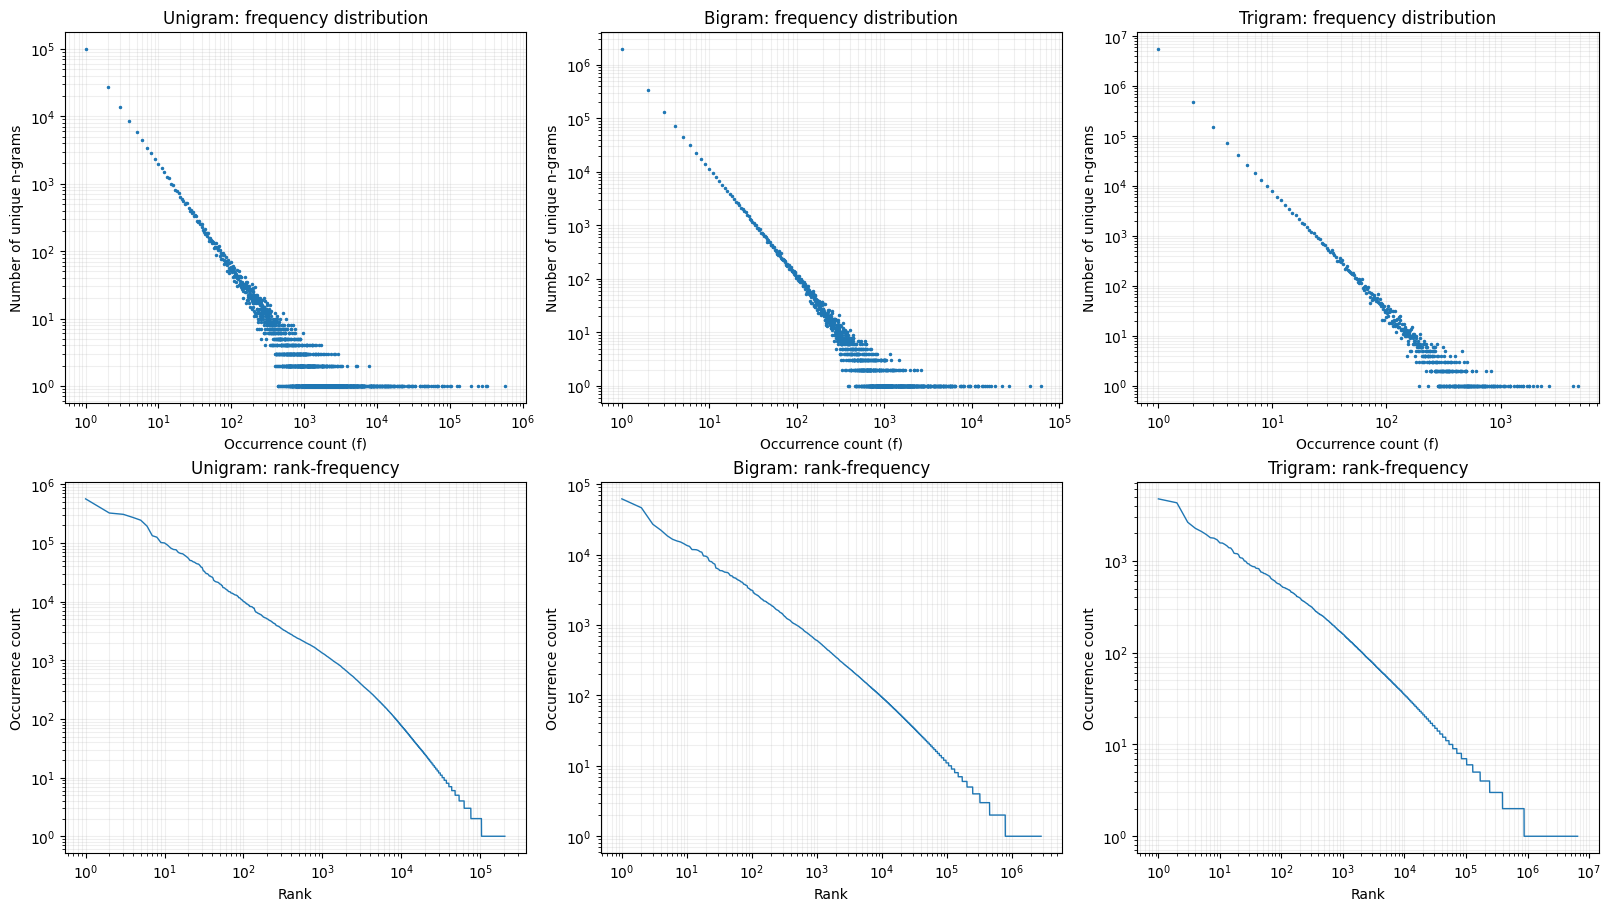

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9), constrained_layout=True)
for column, (n, name) in enumerate([(1, 'Unigram'), (2, 'Bigram'), (3, 'Trigram')]):
    distribution = frequency_of_frequencies[n]
    frequencies = sorted(distribution)
    axes[0, column].loglog(frequencies, [distribution[f] for f in frequencies], '.', markersize=3)
    axes[0, column].set(title=f'{name}: frequency distribution', xlabel='Occurrence count (f)', ylabel='Number of unique n-grams')
    ranked_counts = sorted(counts[n].values(), reverse=True)
    axes[1, column].loglog(range(1, len(ranked_counts) + 1), ranked_counts, linewidth=1)
    axes[1, column].set(title=f'{name}: rank-frequency', xlabel='Rank', ylabel='Occurrence count')
    for row in (0, 1):
        axes[row, column].grid(True, which='both', alpha=0.2)
plt.show()


In [6]:
# Experiment 2 — Mục 16: MLE vs Laplace
import sys
sys.path.insert(0, str(ROOT / 'WEEK2'))
from ngram_lm import load_documents, run_smoothing_experiment, save_experiment_results

# Chạy toàn corpus; chia document 80/10/10, seed 42; vocabulary học từ train.
# Từ xuất hiện <= 1 lần và OOV được ánh xạ sang <UNK>.
smoothing_results = run_smoothing_experiment(load_documents(DATA_PATH), seed=42, unk_cutoff=1)
save_experiment_results(smoothing_results, ROOT / 'WEEK2' / 'results.csv')
rows = ['| Model | Smoothing | Train PPL | Validation PPL | Test PPL |',
        '|---|---|---:|---:|---:|']
for row in smoothing_results:
    rows.append(f"| {row['model']} | {row['smoothing']} | {row['train_ppl']:.6f} | {row['validation_ppl']:.6f} | {row['test_ppl']:.6f} |")
display(Markdown('\n'.join(rows)))
# Cấu hình, kết quả toàn corpus và giải thích: WEEK2/experiment2.md


| Model | Smoothing | Train PPL | Validation PPL | Test PPL |
|---|---|---:|---:|---:|
| Bigram | MLE | 196.202774 | inf | inf |
| Bigram | Laplace | 3650.687142 | 4248.123128 | 4215.609937 |
| Trigram | MLE | 16.855170 | inf | inf |
| Trigram | Laplace | 16944.928020 | 26597.097918 | 26499.687343 |

## Experiment 3 — Perplexity (Mục 19)

So sánh unigram, bigram và trigram trên cùng corpus, chia theo document thành train/validation/test = 80%/10%/10%, seed 42. Vocabulary chỉ học từ training; từ xuất hiện tối đa một lần trong training và từ OOV được ánh xạ sang `<UNK>`. Preprocessing dùng chung với Experiment 2: English Punkt, lowercase, giữ từ/số và apostrophe nội bộ, không BOS/EOS, không nối n-gram qua câu.

Mỗi câu bắt đầu bằng unigram, tiếp theo là bigram nếu mô hình có bậc >= 2, rồi sử dụng bậc của mô hình. PPL được tính bằng `exp(-sum(log probabilities) / total_tokens)`, với cùng số token đánh giá ở mọi mô hình. Bảng Laplace cho phép so sánh hữu hạn trên dữ liệu giữ lại; bảng MLE thể hiện tác động của zero probability. Không so sánh PPL giữa hai cấu hình vocabulary khác nhau.

Cell dưới chạy toàn corpus, hiển thị thống kê các split và hai bảng PPL, rồi lưu `WEEK2/experiment3_results.csv`. Chỉ huấn luyện trên train; validation/test không tham gia đếm hoặc xây vocabulary.

In [ ]:
# Experiment 3 — Mục 19: Unigram / Bigram / Trigram
import csv
import math
import sys
from copy import copy
from pathlib import Path
from IPython.display import display, Markdown

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'data' / 'c4-train.00000-of-01024-30K.json').is_file())
if str(ROOT / 'WEEK2') not in sys.path:
    sys.path.insert(0, str(ROOT / 'WEEK2'))
from ngram_lm import (NGramLanguageModel, load_documents,
                            split_documents, iter_tokenized_sentences)

DATA_PATH = ROOT / 'data' / 'c4-train.00000-of-01024-30K.json'
SEED, UNK_CUTOFF = 42, 1
document_splits_3 = split_documents(load_documents(DATA_PATH), seed=SEED)
sentence_splits_3 = [list(iter_tokenized_sentences(docs)) for docs in document_splits_3]
split_names_3 = ['train', 'validation', 'test']
split_rows_3 = ['| Split | Documents | Sentences | Tokens |', '|---|---:|---:|---:|']
for name, docs, sentences in zip(split_names_3, document_splits_3, sentence_splits_3):
    split_rows_3.append(f'| {name} | {len(docs):,} | {len(sentences):,} | {sum(map(len, sentences)):,} |')
display(Markdown('\n'.join(split_rows_3)))

# Fit only on train. Reuse its counts for every order and smoothing setting.
# copy() shares the read-only counts; changing n/smoothing does not retrain.
base_model_3 = NGramLanguageModel(3, 'mle', unk_cutoff=UNK_CUTOFF)
base_model_3.fit_tokenized(sentence_splits_3[0])
perplexity_results_3 = []
for smoothing in ('mle', 'laplace'):
    for n, name in ((1, 'Unigram'), (2, 'Bigram'), (3, 'Trigram')):
        model_3 = copy(base_model_3)
        model_3.n, model_3.smoothing = n, smoothing
        row = {'model': name, 'smoothing': smoothing,
               'vocabulary_size': len(model_3.vocabulary),
               'seed': SEED, 'unk_cutoff': UNK_CUTOFF}
        for split_name, sentences in zip(split_names_3, sentence_splits_3):
            row[split_name + '_ppl'] = model_3.perplexity(sentences)
        perplexity_results_3.append(row)

def show_ppl_3(value):
    return 'inf' if math.isinf(value) else f'{value:.6f}'

# Same preprocessing, same token denominator and same vocabulary in both tables.
for smoothing in ('mle', 'laplace'):
    rows_3 = [f'### {smoothing.upper()}',
              '| Model | Train PPL | Validation PPL | Test PPL |',
              '|---|---:|---:|---:|']
    for row in perplexity_results_3:
        if row['smoothing'] == smoothing:
            rows_3.append(f"| {row['model']} | {show_ppl_3(row['train_ppl'])} | {show_ppl_3(row['validation_ppl'])} | {show_ppl_3(row['test_ppl'])} |")
    display(Markdown('\n'.join(rows_3)))

experiment3_csv = ROOT / 'WEEK2' / 'experiment3_results.csv'
with experiment3_csv.open('w', encoding='utf-8', newline='') as stream:
    writer = csv.DictWriter(stream, fieldnames=list(perplexity_results_3[0]))
    writer.writeheader()
    writer.writerows(perplexity_results_3)
print('Vocabulary:', len(base_model_3.vocabulary))
print('Saved:', experiment3_csv)


| Split | Documents | Sentences | Tokens |
|---|---:|---:|---:|
| train | 24,000 | 501,775 | 8,855,045 |
| validation | 3,000 | 60,940 | 1,060,081 |
| test | 3,000 | 60,852 | 1,056,946 |

### MLE
| Model | Train PPL | Validation PPL | Test PPL |
|---|---:|---:|---:|
| Unigram | 1923.927641 | 1705.509888 | 1693.166627 |
| Bigram | 196.263959 | inf | inf |
| Trigram | 16.890113 | inf | inf |

### LAPLACE
| Model | Train PPL | Validation PPL | Test PPL |
|---|---:|---:|---:|
| Unigram | 1925.746592 | 1710.210371 | 1697.859400 |
| Bigram | 3648.453327 | 4244.946203 | 4212.145647 |
| Trigram | 16918.661581 | 26548.846895 | 26445.568152 |

Vocabulary: 91656
Saved: D:\HUS\NLP\WEEK2\experiment3_results.csv


### Giải thích kết quả

Kết quả toàn corpus: training PPL của MLE giảm từ 1923.927641 (unigram) xuống 196.263959 (bigram) rồi 16.890113 (trigram), nhưng bigram/trigram đều có validation/test PPL vô hạn. Với Laplace, unigram có test PPL 1697.859400, thấp hơn bigram (4212.145647) và trigram (26445.568152) trong cấu hình này. Điều đó cho thấy tăng bậc không bảo đảm cải thiện trên dữ liệu giữ lại. Unigram có held-out PPL thấp hơn training có thể do phân bố từ ở các split khác nhau; đây không phải lỗi công thức hoặc bằng chứng rò rỉ dữ liệu. Mô hình vẫn chỉ được fit trên train.

**Tại sao training perplexity thay đổi?** Với MLE, tăng bậc cung cấp thêm thông tin về các từ trước đó và cho phép mô hình gán xác suất cao cho những tổ hợp đã quan sát. Trong thí nghiệm này, training PPL của trigram thấp hơn bigram. Vì các vị trí đầu câu dùng bậc thấp hơn, kết quả còn phụ thuộc quy ước xử lý đầu câu. Với Laplace, cộng 1 vào mọi khả năng làm giảm xác suất của nhiều sự kiện phổ biến. Vocabulary lớn và context có ít quan sát khiến smoothing ảnh hưởng mạnh, nên tăng bậc có thể làm cả training PPL tăng.

**Tại sao validation/test có thể không cải thiện?** Context dài hơn tạo nhiều tổ hợp hơn, trong khi mỗi tổ hợp có ít dữ liệu hơn. MLE gán xác suất 0 cho n-gram chưa thấy, dẫn đến corpus PPL vô hạn; ánh xạ OOV sang `<UNK>` không loại bỏ mọi n-gram chưa thấy. Laplace cho xác suất dương nhưng với context hiếm hoặc chưa thấy, phân phối bị kéo về gần đều trên vocabulary. Vì vậy thêm context không bảo đảm dự đoán tốt hơn trên dữ liệu mới.

**Dấu hiệu overfitting.** Training PPL thấp nhưng validation/test PPL cao hơn nhiều hoặc vô hạn cho thấy mô hình khớp dữ liệu đã thấy nhưng tổng quát hóa kém. Cụ thể, trigram MLE có training PPL thấp hơn bigram MLE, trong khi cả hai có validation/test PPL vô hạn. Giá trị vô hạn thể hiện thiếu coverage; chỉ riêng bảng này chưa định lượng được mô hình MLE nào tốt hơn trên held-out. Với Laplace, xem đồng thời giá trị held-out và khoảng cách train–held-out; không chọn mô hình chỉ bằng training PPL.

**Tác động của corpus size.** Corpus lớn hơn thường cung cấp nhiều lần quan sát cho context, giảm sparsity và giúp ước lượng xác suất ổn định hơn. Trigram có thể hưởng lợi từ lượng dữ liệu bổ sung, nhưng không được bảo đảm thắng: thêm dữ liệu cũng có thể thêm vocabulary và n-gram mới. Thí nghiệm này dùng một kích thước corpus, nên nhận định về corpus size là giải thích cơ chế, chưa phải kết quả của phép so sánh nhiều kích thước. Để kiểm chứng, giữ cố định validation/test và quy ước vocabulary khi thay đổi lượng training data.


## Experiment 4 — Context length (Mục 23)

Đo unigram, bigram và trigram trên cùng split train/validation/test. Báo cáo PPL và số n-gram chưa xuất hiện trong training trên từng split. Seed 42, chia document 80/10/10, từ có count <= 1 được thay bằng `<UNK>` dựa trên train. Chạy cả MLE và Laplace để quan sát zero probability và tác động smoothing. Cell lưu bảng vào `WEEK2/context_length_results.csv`.


In [ ]:
# Experiment 4 — Mục 23: ảnh hưởng của độ dài context
import csv
import math
import sys
from collections import Counter
from pathlib import Path
from IPython.display import display, Markdown

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'data' / 'c4-train.00000-of-01024-30K.json').is_file())
if str(ROOT / 'WEEK2') not in sys.path:
    sys.path.insert(0, str(ROOT / 'WEEK2'))
from ngram_lm import (NGramLanguageModel, load_documents, split_documents,
                      iter_tokenized_sentences, UNK_TOKEN)

DATA_PATH = ROOT / 'data' / 'c4-train.00000-of-01024-30K.json'
document_splits_23 = split_documents(load_documents(DATA_PATH), seed=42)
sentence_splits_23 = [list(iter_tokenized_sentences(docs)) for docs in document_splits_23]
train_counts_23 = Counter(word for sent in sentence_splits_23[0] for word in sent)
known_23 = {word for word, count in train_counts_23.items() if count > 1}

def replace_rare_23(sentences):
    return [[word if word in known_23 else UNK_TOKEN for word in sent] for sent in sentences]

mapped_splits_23 = [replace_rare_23(split) for split in sentence_splits_23]
results_23 = []
for smoothing in ('mle', 'laplace'):
    for n, name in ((1, 'Unigram'), (2, 'Bigram'), (3, 'Trigram')):
        model = NGramLanguageModel(n, smoothing, unk_cutoff=1).fit_tokenized(sentence_splits_23[0])
        row = {'model': name, 'smoothing': smoothing, 'vocabulary_size': len(model.vocabulary)}
        for split_name, sentences in zip(('train', 'validation', 'test'), sentence_splits_23):
            row[split_name + '_ppl'] = model.perplexity(sentences)
        observed_train = set(model.counts[n])
        for split_name, sentences in zip(('train', 'validation', 'test'), mapped_splits_23):
            total = unseen = 0
            for sentence in sentences:
                ngrams = list(zip(*(sentence[i:] for i in range(n))))
                total += len(ngrams)
                unseen += sum(ngram not in observed_train for ngram in ngrams)
            row[split_name + '_unseen'] = unseen
            row[split_name + '_ngrams'] = total
        results_23.append(row)

rows_23 = ['| Model | Smoothing | Train PPL | Validation PPL | Test PPL | Unseen train / valid / test n-grams |',
           '|---|---|---:|---:|---:|---:|']
for row in results_23:
    fmt = lambda x: 'inf' if math.isinf(x) else f'{x:.6f}'
    unseen = ' / '.join(f"{row[s+'_unseen']:,}/{row[s+'_ngrams']:,}" for s in ('train','validation','test'))
    rows_23.append(f"| {row['model']} | {row['smoothing']} | {fmt(row['train_ppl'])} | {fmt(row['validation_ppl'])} | {fmt(row['test_ppl'])} | {unseen} |")
display(Markdown('\n'.join(rows_23)))

out_23 = ROOT / 'WEEK2' / 'context_length_results.csv'
with out_23.open('w', encoding='utf-8', newline='') as stream:
    writer = csv.DictWriter(stream, fieldnames=list(results_23[0]))
    writer.writeheader()
    writer.writerows(results_23)
print('Split: document 80/10/10, seed=42; rare cutoff=1; vocabulary:', len(known_23) + 1)
print('Saved:', out_23)


| Model | Smoothing | Train PPL | Validation PPL | Test PPL | Unseen train/valid/test n-grams (unseen/total) |
|---|---|---:|---:|---:|---|
| Unigram | mle | 1923.927641 | 1705.509888 | 1693.166627 | 0/8,855,045; 0/1,060,081; 0/1,056,946 |
| Bigram | mle | 196.263959 | inf | inf | 0/8,353,270; 206,596/999,141; 207,343/996,094 |
| Trigram | mle | 16.890113 | inf | inf | 0/7,859,733; 586,645/939,169; 582,840/936,324 |
| Unigram | laplace | 1925.746592 | 1710.210371 | 1697.859400 | 0/8,855,045; 0/1,060,081; 0/1,056,946 |
| Bigram | laplace | 3648.453327 | 4244.946203 | 4212.145647 | 0/8,353,270; 206,596/999,141; 207,343/996,094 |
| Trigram | laplace | 16918.661581 | 26548.846895 | 26445.568152 | 0/7,859,733; 586,645/939,169; 582,840/936,324 |

Split: document 80/10/10, seed=42; rare cutoff=1; vocabulary: 91656
Saved: D:\HUS\NLP\WEEK2\context_length_results.csv


### Câu hỏi cần tự trả lời dựa trên bảng

Dùng validation/test PPL cùng số unseen n-gram để giải thích liệu context dài hơn có luôn tốt hơn không. So sánh khoảng cách train với held-out để nhận diện overfitting, và lưu ý corpus size giới hạn số context dài có thể quan sát được. Chính sách lab yêu cầu sinh viên tự giải thích kết quả và tự làm error analysis/reflection; hãy viết phần diễn giải bằng nhận xét của bạn.
